### Imports


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Lendo dados

In [2]:
df = pd.read_csv('../data/marketing_AB.csv', sep=',')

## Check de qualidade dos dados

In [3]:
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   Unnamed: 0     588101 non-null  int64
 1   user id        588101 non-null  int64
 2   test group     588101 non-null  str  
 3   converted      588101 non-null  bool 
 4   total ads      588101 non-null  int64
 5   most ads day   588101 non-null  str  
 6   most ads hour  588101 non-null  int64
dtypes: bool(1), int64(4), str(2)
memory usage: 27.5 MB


In [5]:
df.shape

(588101, 7)

In [6]:
df.describe()

,Unnamed: 0,user id,total ads,most ads hour
count,588101.000000,5.881010e+05,588101.000000,588101.000000
mean,294050.000000,1.310692e+06,24.820876,14.469061
std,169770.279668,2.022260e+05,43.715181,4.834634
min,0.000000,9.000000e+05,1.000000,0.000000
25%,147025.000000,1.143190e+06,4.000000,11.000000
50%,294050.000000,1.313725e+06,13.000000,14.000000
75%,441075.000000,1.484088e+06,27.000000,18.000000
max,588100.000000,1.654483e+06,2065.000000,23.000000


In [7]:
df = df.drop(['Unnamed: 0'], axis=1)

#### check de nulos

In [8]:
df.isnull().sum()

user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

In [9]:
df.isna().sum()

user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

### Testes de unicidade sl

In [10]:
df['user id'].is_unique

True

In [11]:
df['user id'].nunique()

588101

In [12]:
df.duplicated().sum()

np.int64(0)

In [41]:
df['user id'].nunique() == len(df)

True

Não há contaminação cruzada, pois não há o mesmo usuário nos dois grupos.

### Check de valores das variaveis categoricas 

#### Test group

In [13]:
df["test group"].value_counts()

test group
ad     564577
psa     23524
Name: count, dtype: int64

In [14]:
# Porcentagem dos grupos
df["test group"].value_counts(normalize=True)*100

test group
ad     96.000007
psa     3.999993
Name: proportion, dtype: float64

Temos então aproximadamente 96% da população no ad e 4% no psa.

#### converted

In [15]:
df['converted'].value_counts()

converted
False    573258
True      14843
Name: count, dtype: int64

In [16]:
# Porcentagem de conversão total
df['converted'].value_counts(normalize=True)*100

converted
False    97.476114
True      2.523886
Name: proportion, dtype: float64

#### Most ads day

In [17]:
df['most ads day'].value_counts()

most ads day
Friday       92608
Monday       87073
Sunday       85391
Thursday     82982
Saturday     81660
Wednesday    80908
Tuesday      77479
Name: count, dtype: int64

In [18]:
pd.crosstab(df["test group"], df["converted"])

converted,False,True
test group,,
ad,550154,14423
psa,23104,420


### Sanidade das variáveis numéricas
Check para as perguntas:

- Variáveis não podem ser negativas?

- Possível Zero?
 
-  Menor valor?

##### Total ads
 * Não pode ser negativo

In [19]:
df['total ads'].min()

np.int64(1)

In [20]:
df["total ads"].value_counts().sort_index().head(20)

total ads
1     56606
2     39827
3     28661
4     23426
5     29303
6     23409
7     19095
8     16037
9     12546
10    11865
11    11323
12    15154
13    12244
14    10975
15    19031
16    13467
17    14629
18    11731
19     9873
20     9057
Name: count, dtype: int64

#### most ads hour
* Tem que estar entre 0 e 23 horas

In [21]:
print(df['most ads hour'].min())
print(df['most ads hour'].max())

0
23


## EDA

### Distribuição das variáveis

#### converted

In [22]:
df['converted'].value_counts(normalize=True)

converted
False    0.974761
True     0.025239
Name: proportion, dtype: float64

#### total ads

In [23]:
df['total ads'].describe()

count    588101.000000
mean         24.820876
std          43.715181
min           1.000000
25%           4.000000
50%          13.000000
75%          27.000000
max        2065.000000
Name: total ads, dtype: float64

In [24]:
df["total ads"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.999])

0.500     13.0
0.750     27.0
0.900     57.0
0.950     88.0
0.990    202.0
0.999    499.9
Name: total ads, dtype: float64

<Axes: >

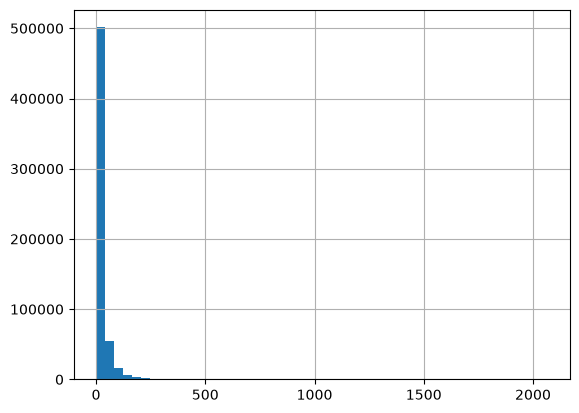

In [25]:
df['total ads'].hist(bins=50)

<Axes: >

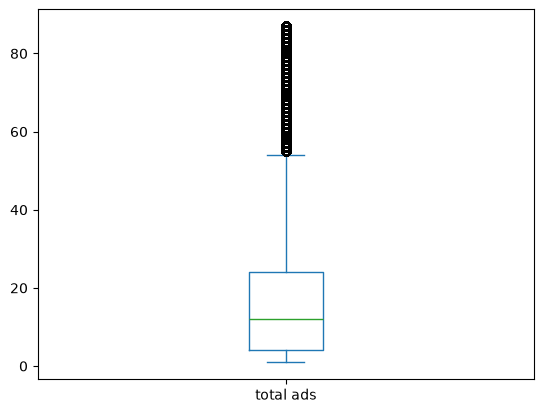

In [26]:
df['total ads'].loc[df['total ads'] < df['total ads'].quantile(0.95)].plot.box()

<Axes: >

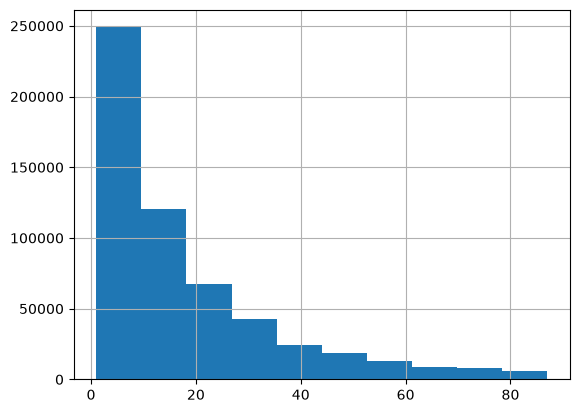

In [27]:
df['total ads'].loc[df['total ads'] < df['total ads'].quantile(0.95)].hist()

Os dados realmnete são muito concentrados apesar da cauda longa, apontando muitos ourliers.

#### Most ads day

In [28]:
df['most ads day'].value_counts()

most ads day
Friday       92608
Monday       87073
Sunday       85391
Thursday     82982
Saturday     81660
Wednesday    80908
Tuesday      77479
Name: count, dtype: int64

<Axes: xlabel='most ads day'>

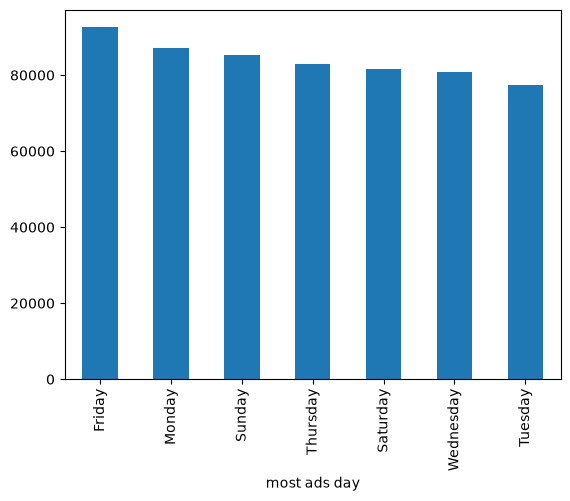

In [29]:
df["most ads day"].value_counts().plot(kind="bar")


Sexta sendo o maior número e terça com menos.

#### ads hour

<Axes: xlabel='most ads hour'>

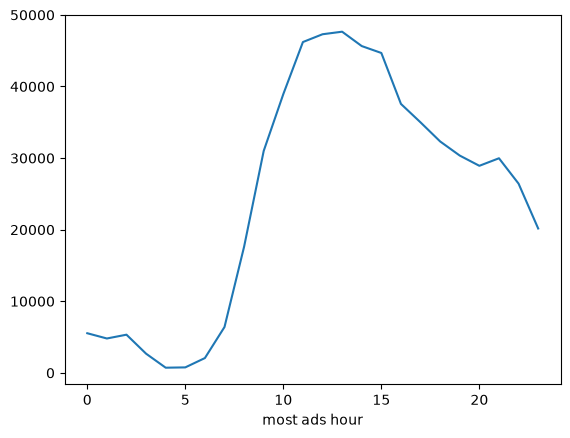

In [30]:
df['most ads hour'].value_counts().sort_index().plot()

Aqui podemos considerar como o comportamento diário.

### Analise bivariada das variáveis

#### Conversão x grupos

In [31]:
converted_by_test = df.groupby('test group')['converted'].mean()
converted_by_test

test group
ad     0.025547
psa    0.017854
Name: converted, dtype: float64

De fato a campanha paga converteu mais do que a organica. Precisamos verificar se é estatísticamente significante. Mas vamos ver como fica em uplift.

In [32]:
uplift = 100 * (converted_by_test['ad'] - converted_by_test['psa']) / converted_by_test['psa']
uplift

np.float64(43.08506402222583)

A campanha paga demonstra um uplift de 43.1% aproximadamente em relação a campanha pública.

#### Relação de conversão e exposição aos anúncios

In [33]:
df["ads_quantile"] = pd.qcut(
    df["total ads"],
    q=5
)

In [34]:
df.groupby("ads_quantile")["converted"].mean()*100

ads_quantile
(0.999, 3.0]      0.211041
(3.0, 8.0]        0.390941
(8.0, 17.0]       0.729168
(17.0, 33.0]      1.715231
(33.0, 2065.0]    9.677944
Name: converted, dtype: float64

In [35]:
df.groupby("test group")["total ads"].describe()

,count,mean,std,min,25%,50%,75%,max
test group,,,,,,,,
ad,564577.0,24.823365,43.750456,1.0,4.0,13.0,27.0,2065.0
psa,23524.0,24.761138,42.860720,1.0,4.0,12.0,26.0,907.0


In [36]:
df.groupby(['test group', 'most ads day'])['converted'].mean()

test group  most ads day
ad          Friday          0.022465
            Monday          0.033241
            Saturday        0.021307
            Sunday          0.024620
            Thursday        0.021637
            Tuesday         0.030440
            Wednesday       0.025356
psa         Friday          0.016303
            Monday          0.022559
            Saturday        0.013996
            Sunday          0.020595
            Thursday        0.020230
            Tuesday         0.014448
            Wednesday       0.015759
Name: converted, dtype: float64

In [37]:
pd.crosstab(df['converted'], df['most ads day'], normalize='index')

most ads day,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
converted,,,,,,,
False,0.157959,0.146908,0.139450,0.145312,0.141633,0.131122,0.137617
True,0.138584,0.192481,0.115812,0.140807,0.120596,0.155764,0.135956


In [38]:
pd.crosstab(df['converted'], df['most ads day'], normalize=True)

most ads day,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
converted,,,,,,,
False,0.153972,0.143200,0.135931,0.141644,0.138058,0.127813,0.134144
True,0.003498,0.004858,0.002923,0.003554,0.003044,0.003931,0.003431
